# Podstawowa analiza zbioru AI4I 2020

Poznamy dane z pliku `ai4i2020.csv`, sprawdzimy ich kompletność i przygotujemy kilka wykresów. Każda komórka przedstawia osobny krok. Uruchamiaj je od góry, korzystając z kernela **Python (.venv)**.

## 1. Importy i wczytanie danych

Używamy `pandas` do analizy danych, `seaborn` do wykresów i `matplotlib` do ich formatowania.

In [1]:
from math import pi
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV, cross_val_predict
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, make_scorer, precision_score

sns.set_theme(style="whitegrid", rc={"figure.figsize": (8, 4)})
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import balanced_accuracy_score, roc_auc_score, average_precision_score

In [2]:
df = pd.read_csv("datasets/ai4i2020.csv")
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## 2. Podstawowe informacje

`UDI` i `Product ID` to identyfikatory, a `Type` to kategoria produktu. Pomiary obejmują temperatury w kelwinach, prędkość obrotową, moment obrotowy i zużycie narzędzia. `Machine failure` oznacza awarię: **0 — brak awarii, 1 — awaria**. Kolumny `TWF`, `HDF`, `PWF`, `OSF` i `RNF` są binarnymi oznaczeniami rodzajów awarii.

In [3]:
print(f"Liczba wierszy: {df.shape[0]}")
print(f"Liczba kolumn: {df.shape[1]}")

Liczba wierszy: 10000
Liczba kolumn: 14


`info()` pokazuje nazwy kolumn, typy danych oraz liczbę niepustych wartości.

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

Sprawdzamy braki w każdej kolumnie oraz liczbę powtórzonych całych wierszy.

In [5]:
df.isna().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

## 3. Statystyki opisowe

Wybieramy pięć pomiarów. `describe()` podaje m.in. średnią, odchylenie standardowe, minimum, maksimum i kwartyle. Nie uwzględniamy identyfikatorów ani oznaczeń awarii.

In [7]:
kolumny_pomiarowe = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
]

df[kolumny_pomiarowe].describe().round(2)

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
count,10000.0,10000.00,10000.00,10000.00,10000.00
mean,300.0,310.01,1538.78,39.99,107.95
std,2.0,1.48,179.28,9.97,63.65
min,295.3,305.70,1168.00,3.80,0.00
25%,298.3,308.80,1423.00,33.20,53.00
50%,300.1,310.10,1503.00,40.10,108.00
75%,301.5,311.10,1612.00,46.80,162.00
max,304.5,313.80,2886.00,76.60,253.00


Sprawdzamy liczebność kategorii produktów i procent obserwacji z awarią.

In [8]:
df["Type"].value_counts()

Type
L    6000
M    2997
H    1003
Name: count, dtype: int64

In [9]:
udzial_awarii = df["Machine failure"].mean() * 100
print(f"Obserwacje z awarią: {udzial_awarii:.2f}%")

Obserwacje z awarią: 3.39%


## 4. Przykładowe wykresy

### Liczba obserwacji z awarią i bez awarii

Wykres słupkowy pozwala porównać liczebności obu grup.

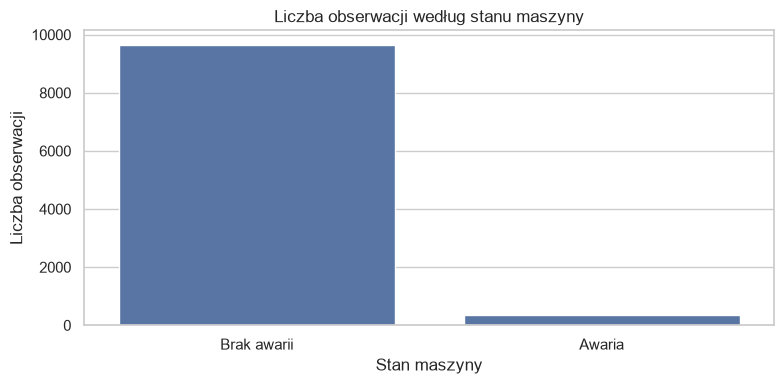

In [10]:
sns.countplot(data=df, x="Machine failure", order=[0, 1])
plt.xticks([0, 1], ["Brak awarii", "Awaria"])
plt.xlabel("Stan maszyny")
plt.ylabel("Liczba obserwacji")
plt.title("Liczba obserwacji według stanu maszyny")
plt.tight_layout()
plt.show()

### Rozkład prędkości obrotowej

Histogram grupuje pomiary w przedziały i pokazuje, które wartości występują najczęściej.

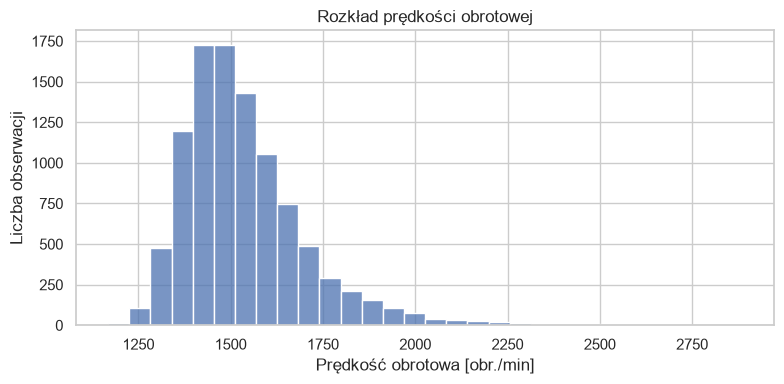

In [11]:
sns.histplot(data=df, x="Rotational speed [rpm]", bins=30)
plt.xlabel("Prędkość obrotowa [obr./min]")
plt.ylabel("Liczba obserwacji")
plt.title("Rozkład prędkości obrotowej")
plt.tight_layout()
plt.show()

### Czy sama prędkość obrotowa pozwala rozróżnić awarię?

Porównujemy prędkość w dwóch grupach na **wykresie pudełkowym**. Linia w pudełku to mediana, a pudełko obejmuje środkowe 50% pomiarów. Wąsy i punkty pokazują pozostały rozrzut danych. Jeśli grupy występują przy podobnych prędkościach, nie można ich jednoznacznie rozdzielić na podstawie samej prędkości.

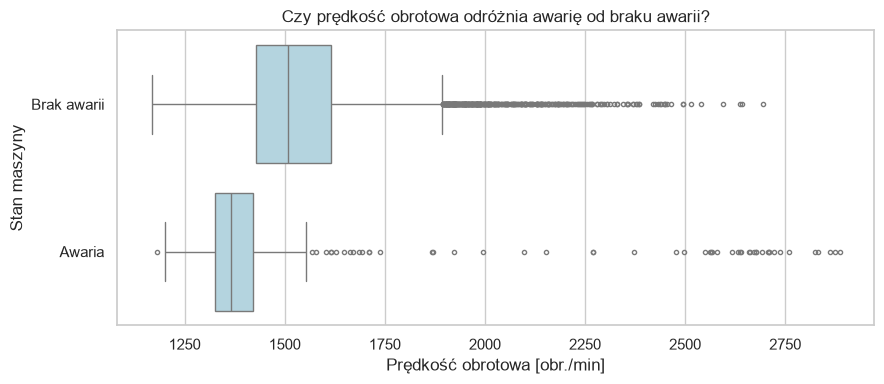

In [12]:
plt.figure(figsize=(9, 4))
sns.boxplot(data=df, x="Rotational speed [rpm]", y="Machine failure",
            orient="h", order=[0, 1], color="lightblue", fliersize=3)
plt.yticks([0, 1], ["Brak awarii", "Awaria"])
plt.xlabel("Prędkość obrotowa [obr./min]")
plt.ylabel("Stan maszyny")
plt.title("Czy prędkość obrotowa odróżnia awarię od braku awarii?")
plt.tight_layout()
plt.show()

**Wniosek:** prędkość pomaga odróżniać grupy, ale nie daje pewnego rozróżnienia. Mediana wynosi **1365 obr./min dla awarii** i **1507 obr./min dla braku awarii**. Większość obserwacji z awarią ma niższe prędkości, lecz awarie występują też przy bardzo wysokich prędkościach. Zakresy obu grup mocno się nakładają, więc jeden próg prędkości nie oddzieli wszystkich awarii od poprawnej pracy. Punkty poza wąsami nie muszą oznaczać błędów danych.

### Moment obrotowy a awaria

Wykres pudełkowy porównuje medianę i rozrzut pomiarów. Punkty poza wąsami pokazują wartości odstające według reguły wykresu; nie muszą oznaczać błędów w danych.

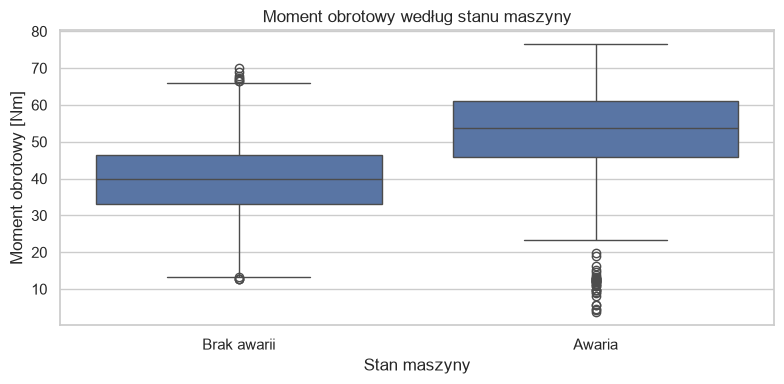

In [13]:
sns.boxplot(data=df, x="Machine failure", y="Torque [Nm]", order=[0, 1])
plt.xticks([0, 1], ["Brak awarii", "Awaria"])
plt.xlabel("Stan maszyny")
plt.ylabel("Moment obrotowy [Nm]")
plt.title("Moment obrotowy według stanu maszyny")
plt.tight_layout()
plt.show()

### Prędkość obrotowa a moment obrotowy

Każdy punkt przedstawia jeden rekord. Małe, częściowo przezroczyste punkty ułatwiają obserwację zagęszczenia danych.

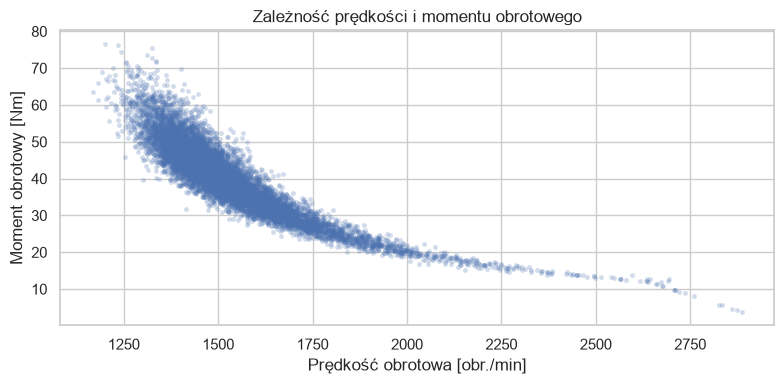

In [14]:
sns.scatterplot(data=df, x="Rotational speed [rpm]", y="Torque [Nm]",
                s=12, alpha=0.25, linewidth=0)
plt.xlabel("Prędkość obrotowa [obr./min]")
plt.ylabel("Moment obrotowy [Nm]")
plt.title("Zależność prędkości i momentu obrotowego")
plt.tight_layout()
plt.show()

### Korelacje między pomiarami

Korelacja Pearsona opisuje siłę zależności liniowej: wartości bliskie 1 oznaczają zależność dodatnią, a bliskie −1 — ujemną. Wartość bliska 0 nie wyklucza zależności nieliniowej. Korelacja nie dowodzi związku przyczynowego.

In [15]:
korelacje = df[kolumny_pomiarowe].corr()
korelacje

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
Air temperature [K],1.000000,0.876107,0.022670,-0.013778,0.013853
Process temperature [K],0.876107,1.000000,0.019277,-0.014061,0.013488
Rotational speed [rpm],0.022670,0.019277,1.000000,-0.875027,0.000223
Torque [Nm],-0.013778,-0.014061,-0.875027,1.000000,-0.003093
Tool wear [min],0.013853,0.013488,0.000223,-0.003093,1.000000


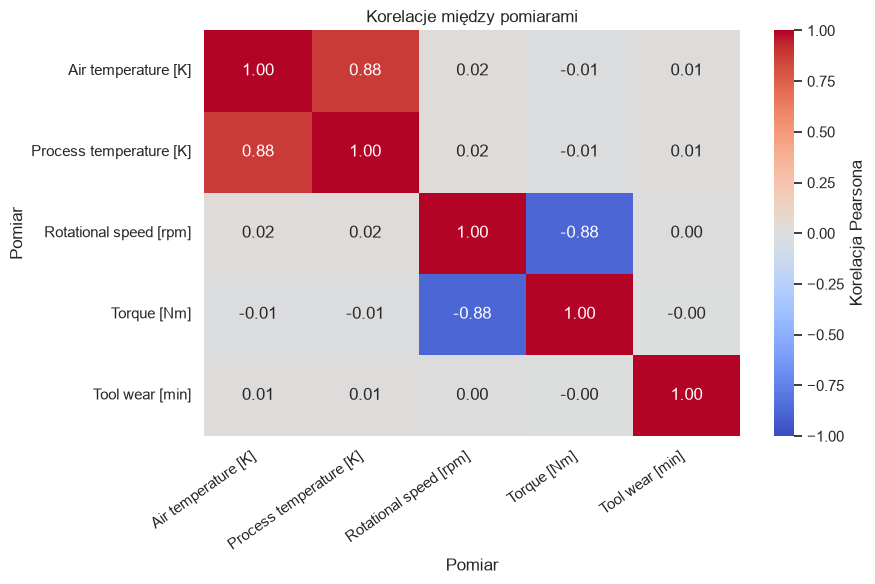

In [16]:
plt.figure(figsize=(9, 6))
sns.heatmap(korelacje, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, center=0,
            cbar_kws={"label": "Korelacja Pearsona"})
plt.title("Korelacje między pomiarami")
plt.xlabel("Pomiar")
plt.ylabel("Pomiar")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Korelacja Machine failure z rodzajami awarii

Obliczamy korelację Pearsona między `Machine failure` a `TWF`, `HDF`, `PWF`, `OSF` i `RNF`. Wszystkie te kolumny mają wartości 0 lub 1; dla takich zmiennych korelacja Pearsona jest równa współczynnikowi phi. Dodatnia wartość oznacza tendencję do wspólnego występowania wartości 1.

In [17]:
kolumny_awarii = ["Machine failure", "TWF", "HDF", "PWF", "OSF", "RNF"]
korelacje_awarii = df[kolumny_awarii].corr()
korelacje_z_awaria = korelacje_awarii.loc[["Machine failure"], kolumny_awarii[1:]]
korelacje_z_awaria.round(3)

,TWF,HDF,PWF,OSF,RNF
Machine failure,0.363,0.576,0.523,0.531,0.005


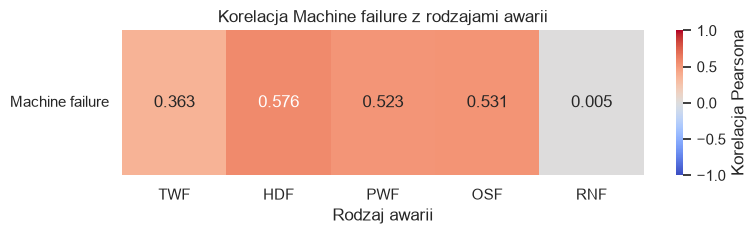

In [18]:
plt.figure(figsize=(8, 2.5))
sns.heatmap(korelacje_z_awaria, annot=True, fmt=".3f",
            cmap="coolwarm", vmin=-1, vmax=1, center=0,
            cbar_kws={"label": "Korelacja Pearsona"})
plt.xlabel("Rodzaj awarii")
plt.ylabel("")
plt.yticks(rotation=0)
plt.title("Korelacja Machine failure z rodzajami awarii")
plt.tight_layout()
plt.show()

**Wniosek:** najsilniejsza dodatnia korelacja występuje dla **HDF (0,576)**, następnie **OSF (0,531)** i **PWF (0,523)**. Dla **TWF** wynosi **0,363**, a dla **RNF** jest bliska zeru (**0,005**). Kolumny te opisują rodzaje awarii, więc korelacja pokazuje współwystępowanie oznaczeń. Jej wielkość zależy także od częstości danego rodzaju awarii; nie jest odsetkiem awarii.

## 5. Najważniejsze obserwacje

- Zbiór zawiera **10 000 wierszy i 14 kolumn**. Nie ma brakujących wartości ani powtórzonych całych wierszy.
- Awarię oznaczono w **339 rekordach (3,39%)**, więc obie grupy są wyraźnie nierówne liczebnie.
- Najliczniejszą kategorią produktu jest **L**: 6000 obserwacji.
- Większe prędkości obrotowe zwykle współwystępują z mniejszym momentem obrotowym. Temperatury powietrza i procesu są dodatnio skorelowane.

**Ćwiczenie:** zmień kolumnę histogramu na `Tool wear [min]` i porównaj kształt rozkładu.

## 6. Przygotowanie cech i zmiennej docelowej

Chcemy przewidywać `Machine failure`. Zapisujemy tę kolumnę jako zmienną docelową `y`, a pozostałe cechy jako `X`.

Usuwamy z cech identyfikatory `UDI` i `Product ID` oraz oznaczenia rodzajów awarii: `TWF`, `HDF`, `PWF`, `OSF` i `RNF`. Oznaczenia awarii są informacją o wyniku, więc ich użycie prowadziłoby do wycieku informacji do modelu. Oryginalny zbiór `df` pozostaje dostępny do analizy.

### Cechy opisujące proces

Dodajemy do `df` trzy cechy obliczane z dostępnych pomiarów:

- **Moc [W]**: moment obrotowy × prędkość obrotowa × 2π/60. Przelicznik zamienia obr./min na rad/s.
- **Różnica temperatur [K]**: temperatura procesu − temperatura powietrza.
- **Obciążenie narzędzia [min·Nm]**: zużycie narzędzia × moment obrotowy. To wskaźnik obciążenia, a nie siła.

Nie wykorzystujemy oznaczeń awarii. Wzory nie uczą się parametrów z danych, więc można je zastosować przed podziałem. Plik CSV pozostaje bez zmian.

In [19]:
df["Power [W]"] = df["Torque [Nm]"] * df["Rotational speed [rpm]"] * 2 * pi / 60
df["Temperature difference [K]"] = df["Process temperature [K]"] - df["Air temperature [K]"]
df["Tool load [min Nm]"] = df["Tool wear [min]"] * df["Torque [Nm]"]

df[["Power [W]", "Temperature difference [K]", "Tool load [min Nm]"]].head()

,Power [W],Temperature difference [K],Tool load [min Nm]
0,6951.590560,10.5,0.0
1,6826.722724,10.5,138.9
2,7749.387543,10.4,247.0
3,5927.504659,10.4,276.5
4,5897.816608,10.5,360.0


In [20]:
y = df["Machine failure"]

kolumny_do_usuniecia = [
    "UDI", "Product ID", "Machine failure",
    "TWF", "HDF", "PWF", "OSF", "RNF",
]
X = df.drop(columns=kolumny_do_usuniecia)
X.head()

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Power [W],Temperature difference [K],Tool load [min Nm]
0,M,298.1,308.6,1551,42.8,0,6951.590560,10.5,0.0
1,L,298.2,308.7,1408,46.3,3,6826.722724,10.5,138.9
2,L,298.1,308.5,1498,49.4,5,7749.387543,10.4,247.0
3,L,298.2,308.6,1433,39.5,7,5927.504659,10.4,276.5
4,L,298.2,308.7,1408,40.0,9,5897.816608,10.5,360.0


Pozostaje dziewięć cech: kategoria produktu `Type`, pięć pomiarów i trzy obliczone cechy procesu. `Type` wymaga zamiany na reprezentację liczbową przed uczeniem klasyfikatora. Sprawdzamy rozmiary `X` i `y`.

In [21]:
print(f"Zbiór cech X: {X.shape[0]} wierszy, {X.shape[1]} kolumn")
print(f"Zmienna docelowa y: {y.shape[0]} wartości")

Zbiór cech X: 10000 wierszy, 9 kolumn
Zmienna docelowa y: 10000 wartości


### Zamiana kategorii `Type` na liczby

Stosujemy kodowanie one-hot: `pd.get_dummies()` zastępuje `Type` trzema kolumnami: `Type_H`, `Type_L` i `Type_M`. Wartość 1 oznacza daną kategorię produktu, a 0 — pozostałe kategorie. Dzięki temu nie przypisujemy kategoriom sztucznej kolejności. Pozostałe cechy zachowują swoje wartości.

In [22]:
X = pd.get_dummies(X, columns=["Type"], dtype=int)
X.head()

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Power [W],Temperature difference [K],Tool load [min Nm],Type_H,Type_L,Type_M
0,298.1,308.6,1551,42.8,0,6951.590560,10.5,0.0,0,0,1
1,298.2,308.7,1408,46.3,3,6826.722724,10.5,138.9,0,1,0
2,298.1,308.5,1498,49.4,5,7749.387543,10.4,247.0,0,1,0
3,298.2,308.6,1433,39.5,7,5927.504659,10.4,276.5,0,1,0
4,298.2,308.7,1408,40.0,9,5897.816608,10.5,360.0,0,1,0


Po kodowaniu zbiór `X` zawiera jedenaście cech liczbowych: pięć pomiarów, trzy obliczone cechy procesu i trzy wskaźniki kategorii produktu.

In [23]:
X.shape

(10000, 11)

## 7. Podział na zbiór uczący i testowy

Przeznaczamy 80% obserwacji do uczenia modelu, a 20% do oceny na danych testowych. `random_state=42` zapewnia powtarzalny podział. Ponieważ awarie są rzadkie, używamy `stratify=y`, aby zachować zbliżony udział obu klas w każdym zbiorze.

In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

Sprawdzamy liczbę obserwacji i udział awarii w obu zbiorach. Model będziemy dopasowywać na `X_train` i `y_train`, a oceniać na `X_test` i `y_test`.

In [25]:
print(f"Zbiór uczący: {X_train.shape[0]} wierszy")
print(f"Zbiór testowy: {X_test.shape[0]} wierszy")
print(f"Udział awarii w zbiorze uczącym: {y_train.mean():.2%}")
print(f"Udział awarii w zbiorze testowym: {y_test.mean():.2%}")

Zbiór uczący: 8000 wierszy
Zbiór testowy: 2000 wierszy
Udział awarii w zbiorze uczącym: 3.39%
Udział awarii w zbiorze testowym: 3.40%


## 8. Klasyfikator bazowy — DummyClassifier

`DummyClassifier` ze strategią `most_frequent` zawsze przewiduje klasę najczęstszą w zbiorze uczącym. Nie wykorzystuje zależności między cechami a awarią. Jego wynik będzie punktem odniesienia dla kolejnego modelu. Dopasowujemy go wyłącznie na danych uczących.

In [26]:
dummy = DummyClassifier(strategy="most_frequent", random_state=42)
dummy.fit(X_train, y_train)

,"strategy strategy: {""most_frequent"", ""prior"", ""stratified"", ""uniform"", ""constant""}, default=""prior""Strategy to use to generate predictions.* ""most_frequent"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit`. The `predict_proba` method returns the matching one-hot encoded vector.* ""prior"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit` (like ""most_frequent""). ``predict_proba`` always returns the empirical class distribution of `y` also known as the empirical class prior distribution.* ""stratified"": the `predict_proba` method randomly samples one-hot vectors from a multinomial distribution parametrized by the empirical class prior probabilities. The `predict` method returns the class label which got probability one in the one-hot vector of `predict_proba`. Each sampled row of both methods is therefore independent and identically distributed.* ""uniform"": generates predictions uniformly at random from the list of unique classes observed in `y`, i.e. each class has equal probability.* ""constant"": always predicts a constant label that is provided by the user. This is useful for metrics that evaluate a non-majority class. .. versionchanged:: 0.24 The default value of `strategy` has changed to ""prior"" in version 0.24.",'most_frequent'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness to generate the predictions when``strategy='stratified'`` or ``strategy='uniform'``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"constant constant: int or str or array-like of shape (n_outputs,), default=NoneThe explicit constant as predicted by the ""constant"" strategy. Thisparameter is useful only for the ""constant"" strategy.",None
Name,Type,Value
"class_prior_ class_prior_: ndarray of shape (n_classes,) or list of such arraysFrequency of each class observed in `y`. For multioutput classificationproblems, this is computed independently for each output.","ndarray[float64](2,)","[0.97,0.03]"
"classes_ classes_: ndarray of shape (n_classes,) or list of such arraysUnique class labels observed in `y`. For multi-output classificationproblems, this attribute is a list of arrays as each output has anindependent set of possible classes.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X` hasfeature names that are all strings.","ndarray[object](11,)","['Air temperature [K]','Process temperature [K]','Rotational speed [rpm]', ...,'Type_H','Type_L','Type_M']"
n_classes_ n_classes_: int or list of intNumber of label for each output.,int,2
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`.,int,11
n_outputs_ n_outputs_: intNumber of outputs.,int,1
sparse_output_ sparse_output_: boolTrue if the array returned from predict is to be in sparse CSC format.Is automatically set to True if the input `y` is passed in sparseformat.,bool,False


Przewidujemy klasy dla zbioru testowego. Accuracy to udział poprawnych przewidywań. W raporcie **precision** mówi, jaka część przewidywanych awarii jest rzeczywistą awarią, **recall** — jaką część rzeczywistych awarii wykryto, a **F1** łączy precision i recall. **Support** to liczba obserwacji danej klasy w zbiorze testowym.

`zero_division=0` przyjmuje wartość 0 dla metryki, której nie można obliczyć z powodu zerowego mianownika, np. precision przy braku przewidywanych awarii.

In [27]:
y_pred_dummy = dummy.predict(X_test)

print(f"Accuracy: {accuracy_score(y_test, y_pred_dummy):.2%}")
print(classification_report(
    y_test, y_pred_dummy,
    labels=[0, 1], target_names=["Brak awarii", "Awaria"],
    digits=3, zero_division=0
))

Accuracy: 96.60%
              precision    recall  f1-score   support

 Brak awarii      0.966     1.000     0.983      1932
      Awaria      0.000     0.000     0.000        68

    accuracy                          0.966      2000
   macro avg      0.483     0.500     0.491      2000
weighted avg      0.933     0.966     0.949      2000



Macierz pomyłek pokazuje liczbę poprawnych i błędnych przewidywań. Wiersze oznaczają rzeczywiste klasy, a kolumny — przewidywane.

In [28]:
macierz_dummy = pd.DataFrame(
    confusion_matrix(y_test, y_pred_dummy, labels=[0, 1]),
    index=["Rzeczywisty brak awarii", "Rzeczywista awaria"],
    columns=["Przewidywany brak awarii", "Przewidywana awaria"],
)
macierz_dummy

,Przewidywany brak awarii,Przewidywana awaria
Rzeczywisty brak awarii,1932,0
Rzeczywista awaria,68,0


### Macierz pomyłek (macierz rozbieżności)

Przedstawiamy tę samą macierz jako mapę cieplną. Wartości na przekątnej oznaczają poprawne przewidywania, a poza przekątną — błędy. Dolne lewe pole pokazuje niewykryte awarie.

Klasą pozytywną jest **awaria (1)**. **TN** oznacza poprawnie przewidziany brak awarii, **FP** — fałszywy alarm, **FN** — niewykrytą awarię, a **TP** — poprawnie wykrytą awarię.

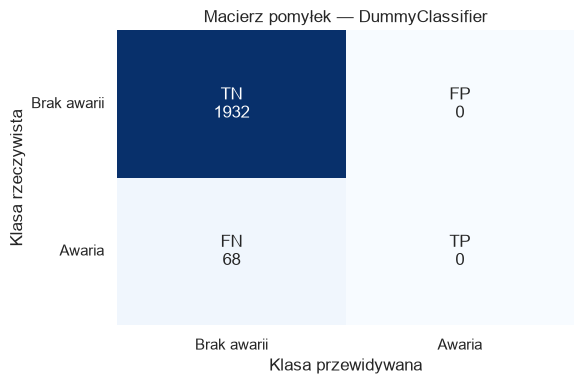

In [29]:
etykiety_dummy = [
    [f"TN\n{macierz_dummy.iloc[0, 0]}", f"FP\n{macierz_dummy.iloc[0, 1]}"],
    [f"FN\n{macierz_dummy.iloc[1, 0]}", f"TP\n{macierz_dummy.iloc[1, 1]}"],
]

plt.figure(figsize=(6, 4))
sns.heatmap(
    macierz_dummy, annot=etykiety_dummy, fmt="", cmap="Blues", cbar=False,
    xticklabels=["Brak awarii", "Awaria"],
    yticklabels=["Brak awarii", "Awaria"],
)
plt.xlabel("Klasa przewidywana")
plt.ylabel("Klasa rzeczywista")
plt.title("Macierz pomyłek — DummyClassifier")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

**Wniosek:** model zawsze przewiduje brak awarii. Uzyskuje **96,60% accuracy**, ponieważ poprawnie klasyfikuje 1932 obserwacje bez awarii. Pomija jednak **wszystkie 68 awarii**: recall i F1 dla klasy `Awaria` wynoszą **0**. Precision dla awarii przyjmuje 0 zgodnie z ustawieniem `zero_division=0`, ponieważ model nie przewiduje żadnej awarii. Wysoka accuracy nie oznacza więc, że model nadaje się do wykrywania awarii. Przy ocenie kolejnego klasyfikatora zwrócimy uwagę przede wszystkim na recall oraz precision dla klasy `Awaria`.

## 9. Klasyfikator awarii — drzewo decyzyjne

Drzewo decyzyjne uczy się reguł dzielących obserwacje na podstawie wartości cech. Używamy `DecisionTreeClassifier(random_state=42)` bez ograniczenia głębokości. Drzewo nie wymaga skalowania cech. Dopasowujemy model wyłącznie na `X_train` i `y_train`; zbiór testowy służy do oceny.

In [30]:
drzewo = DecisionTreeClassifier(random_state=42)
drzewo.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

### Ocena na zbiorze testowym

Korzystamy z tego samego podziału i tych samych metryk co dla `DummyClassifier`. Dla wykrywania awarii szczególnie istotne są precision, recall i F1 klasy `Awaria`. Dodatkowo porównujemy accuracy na zbiorze uczącym i testowym — lepszy wynik na danych uczących może wskazywać na przeuczenie.

In [31]:
y_pred_drzewo = drzewo.predict(X_test)

print(f"Accuracy na zbiorze uczącym: {drzewo.score(X_train, y_train):.2%}")
print(f"Accuracy na zbiorze testowym: {accuracy_score(y_test, y_pred_drzewo):.2%}")
print(classification_report(
    y_test, y_pred_drzewo,
    labels=[0, 1], target_names=["Brak awarii", "Awaria"],
    digits=3, zero_division=0
))

Accuracy na zbiorze uczącym: 100.00%
Accuracy na zbiorze testowym: 98.70%
              precision    recall  f1-score   support

 Brak awarii      0.993     0.993     0.993      1932
      Awaria      0.809     0.809     0.809        68

    accuracy                          0.987      2000
   macro avg      0.901     0.901     0.901      2000
weighted avg      0.987     0.987     0.987      2000



### Macierz pomyłek drzewa decyzyjnego

Klasą pozytywną jest awaria. **TP** oznacza wykryte awarie, **FN** — pominięte awarie, **FP** — fałszywe alarmy, a **TN** — poprawnie przewidziany brak awarii.

In [32]:
macierz_drzewo = pd.DataFrame(
    confusion_matrix(y_test, y_pred_drzewo, labels=[0, 1]),
    index=["Rzeczywisty brak awarii", "Rzeczywista awaria"],
    columns=["Przewidywany brak awarii", "Przewidywana awaria"],
)
macierz_drzewo

,Przewidywany brak awarii,Przewidywana awaria
Rzeczywisty brak awarii,1919,13
Rzeczywista awaria,13,55


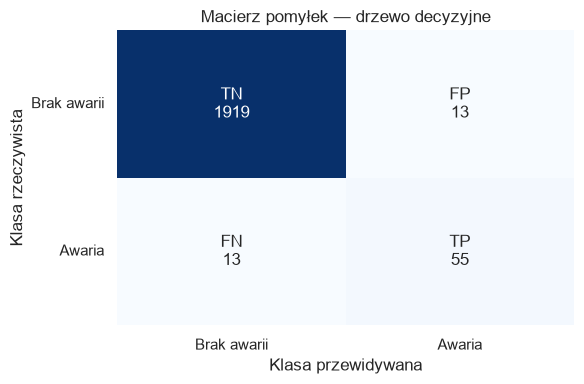

In [33]:
etykiety_drzewo = [
    [f"TN\n{macierz_drzewo.iloc[0, 0]}", f"FP\n{macierz_drzewo.iloc[0, 1]}"],
    [f"FN\n{macierz_drzewo.iloc[1, 0]}", f"TP\n{macierz_drzewo.iloc[1, 1]}"],
]

plt.figure(figsize=(6, 4))
sns.heatmap(
    macierz_drzewo, annot=etykiety_drzewo, fmt="", cmap="Blues", cbar=False,
    xticklabels=["Brak awarii", "Awaria"],
    yticklabels=["Brak awarii", "Awaria"],
)
plt.xlabel("Klasa przewidywana")
plt.ylabel("Klasa rzeczywista")
plt.title("Macierz pomyłek — drzewo decyzyjne")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

**Wniosek:** drzewo bez ograniczenia głębokości, z trzema dodatkowymi cechami procesu, uzyskało **98.70% accuracy** na zbiorze testowym. Wykryło **55 z 68 awarii**, pominęło **13**, a liczba fałszywych alarmów wyniosła **13**. F1 dla awarii wynosi **0.809**. To wynik pojedynczego podziału; dalej stosujemy walidację krzyżową.

## 10. Wizualizacja drzewa decyzyjnego

Pokazujemy pierwsze trzy poziomy wyuczonego drzewa. `max_depth=2` w `plot_tree` ogranicza jedynie rysunek, a nie model.

Węzły pokazują warunek podziału, `gini` (miarę wymieszania klas), `samples` (liczbę obserwacji uczących), `value` (udziały klas w kolejności **[brak awarii, awaria]**) i `class` (przewidywaną klasę). Lewa gałąź spełnia warunek, a prawa go nie spełnia.

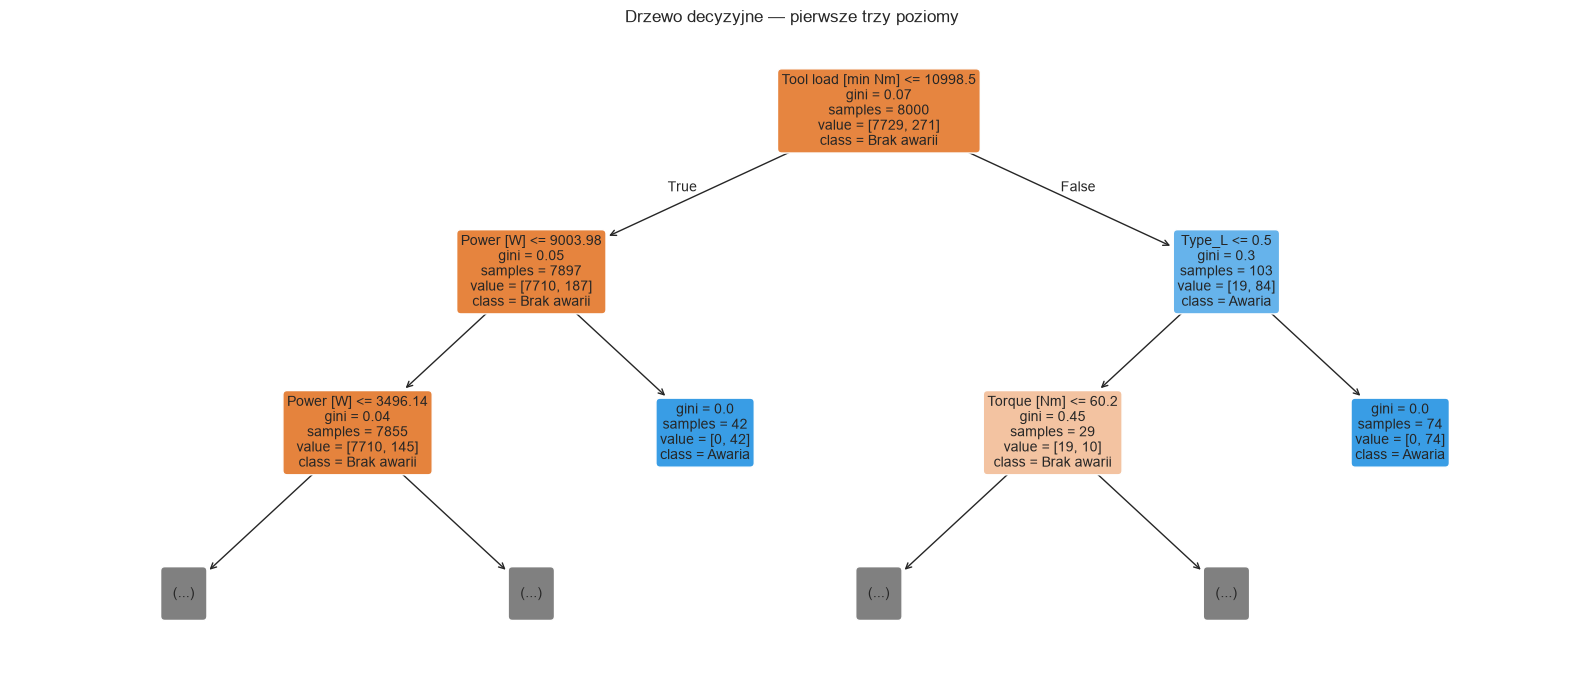

In [34]:
plt.figure(figsize=(16, 7))
plot_tree(
    drzewo,
    max_depth=2,
    feature_names=X_train.columns.tolist(),
    class_names=["Brak awarii", "Awaria"],
    filled=True,
    rounded=True,
    precision=2,
    fontsize=10,
)
plt.title("Drzewo decyzyjne — pierwsze trzy poziomy")
plt.tight_layout()
plt.show()

## 11. Ocena klasyfikatora — 5-krotna walidacja krzyżowa

Oceniamy model `drzewo` utworzony w kodzie jako `DecisionTreeClassifier(random_state=42)`, czyli bez ograniczenia głębokości. Dzielimy **pełny zbiór `X, y`** na pięć części, niezależnie od wcześniejszego podziału train-test. W każdej iteracji model uczy się od nowa na czterech częściach, a na pozostałej części oceniamy jego przewidywania. Każda część pełni raz rolę walidacyjną. Każda obserwacja z pełnego zbioru służy raz do walidacji i cztery razy do uczenia.

`StratifiedKFold` zachowuje zbliżony udział klas w każdej części. `shuffle=True` miesza obserwacje przed podziałem, a `random_state=42` zapewnia powtarzalność. `cross_validate` tworzy osobną kopię modelu dla każdego podziału i nie zmienia wcześniej dopasowanego drzewa.

Obliczamy accuracy oraz precision, recall i F1 dla **awarii (klasa 1)**. Recall pokazuje, jaką część awarii wykrywamy, a precision — jaka część alarmów jest poprawna. F1 łączy obie miary. Wysoka accuracy może wynikać z przewagi obserwacji bez awarii.

In [35]:
walidacja = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

wyniki_cv = cross_validate(
    drzewo, X, y,
    cv=walidacja,
    scoring=["accuracy", "precision", "recall", "f1"],
)

wyniki_podzialow = pd.DataFrame({
    "Accuracy": wyniki_cv["test_accuracy"],
    "Precision": wyniki_cv["test_precision"],
    "Recall": wyniki_cv["test_recall"],
    "F1": wyniki_cv["test_f1"],
}, index=pd.Index(range(1, walidacja.get_n_splits() + 1), name="Podział"))
wyniki_podzialow.round(3)

,Accuracy,Precision,Recall,F1
Podział,,,,
1,0.988,0.824,0.836,0.830
2,0.985,0.744,0.853,0.795
3,0.986,0.806,0.794,0.800
4,0.988,0.806,0.853,0.829
5,0.989,0.848,0.824,0.836


### Średnie wyniki i ich zmienność

Średnia podsumowuje pięć ocen, a odchylenie standardowe pokazuje ich zmienność między podziałami (nie jest przedziałem ufności). Metryki mają wartości od 0 do 1; np. recall równy 0,70 oznacza wykrycie 70% awarii.

In [36]:
podsumowanie_cv = pd.DataFrame({
    "Średnia": wyniki_podzialow.mean(),
    "Odchylenie standardowe": wyniki_podzialow.std(),
})
podsumowanie_cv.round(3)

,Średnia,Odchylenie standardowe
Accuracy,0.987,0.002
Precision,0.805,0.039
Recall,0.832,0.024
F1,0.818,0.019


**Wniosek:** po dodaniu cech procesu dla pełnego `X, y` średnia accuracy wynosi **98.74%**, precision **80.54%**, recall **83.19%**, a F1 **0.818**. Walidacja dotyczy drzewa bez ograniczenia głębokości.

## 12. Dobór głębokości drzewa — GridSearchCV

Sprawdzamy `max_depth`: **wszystkie całkowite głębokości od 3 do 20 włącznie**. `GridSearchCV` ocenia każdą opcję na pełnym `X, y`, wykorzystując ten sam 5-krotny podział `walidacja`. W każdym podziale dopasowuje nowe drzewo wyłącznie na części uczącej.

Wybieramy najwyższą **średnią F1 dla awarii (klasa 1)**. F1 łączy precision i recall. Obliczamy też obie te metryki dla awarii: precision to udział rzeczywistych awarii wśród alarmów, a recall to udział wykrytych awarii. `refit="f1"` wskazuje metrykę używaną do wyboru najlepszego modelu. Po wyborze parametrów `GridSearchCV` automatycznie dopasowuje najlepszy model na całym `X, y`.

Wynik służy do wyboru głębokości. Ponieważ używamy pełnych danych do strojenia, nie jest on niezależną oceną końcową wybranego modelu.

In [37]:
grid_search = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid={"max_depth": range(3, 21)},
    scoring=["f1", "precision", "recall"],
    refit="f1",
    cv=walidacja,
)
grid_search.fit(X, y)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': range(3, 21)}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","['f1', 'precision', ...]"
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'f1'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"verbose verbose: int, default=0Controls the verbo

### Porównanie głębokości

Pokazujemy średnie F1, precision i recall oraz ich odchylenia standardowe między pięcioma podziałami. Wszystkie metryki dotyczą awarii (klasa 1). Pozycja 1 oznacza najlepszą średnią F1.

In [38]:
wyniki_grid = pd.DataFrame(grid_search.cv_results_)
porownanie_glebokosci = wyniki_grid[[
    "param_max_depth",
    "mean_test_f1", "std_test_f1",
    "mean_test_precision", "std_test_precision",
    "mean_test_recall", "std_test_recall",
    "rank_test_f1",
]].copy()
porownanie_glebokosci.columns = [
    "Głębokość",
    "Średnia F1", "Odchylenie F1",
    "Średnia precision", "Odchylenie precision",
    "Średnia recall", "Odchylenie recall",
    "Pozycja F1",
]
porownanie_glebokosci.round(3)

,Głębokość,Średnia F1,Odchylenie F1,Średnia precision,Odchylenie precision,Średnia recall,Odchylenie recall,Pozycja F1
0,3,0.683,0.027,1.000,0.000,0.519,0.030,18
1,4,0.692,0.027,0.994,0.012,0.531,0.028,17
2,5,0.894,0.013,0.980,0.017,0.823,0.027,1
3,6,0.894,0.013,1.000,0.000,0.808,0.020,2
4,7,0.887,0.015,0.979,0.017,0.811,0.023,3
5,8,0.881,0.012,0.953,0.024,0.820,0.025,4
6,9,0.875,0.016,0.943,0.025,0.817,0.023,5
7,10,0.849,0.024,0.882,0.059,0.820,0.021,6
8,11,0.842,0.024,0.868,0.054,0.820,0.021,7
9,12,0.827,0.026,0.837,0.057,0.820,0.019,9


In [39]:
print(f"Najlepsza głębokość: {grid_search.best_params_['max_depth']}")
print(f"Najlepsza średnia F1: {grid_search.best_score_:.3f}")

najlepsze_drzewo = grid_search.best_estimator_

Najlepsza głębokość: 5
Najlepsza średnia F1: 0.894


**Wniosek:** po dodaniu cech procesu najlepsza spośród głębokości 3–20 jest **5**, ze średnią F1 **0.894** w 5-krotnej walidacji na pełnym `X, y`. Dopasowany model jest dostępny jako `najlepsze_drzewo`.

### F1 a głębokość drzewa

Każdy punkt pokazuje średnią F1 dla awarii z 5-krotnej walidacji krzyżowej. Przerywana linia wskazuje głębokość wybraną przez GridSearchCV.

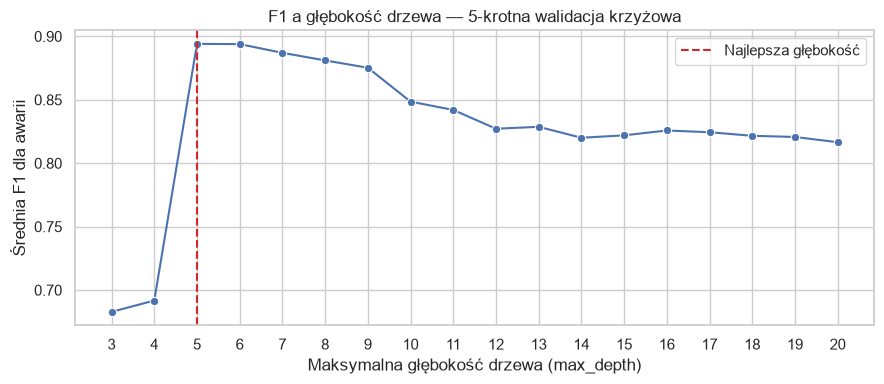

In [40]:
plt.figure(figsize=(9, 4))
sns.lineplot(
    data=porownanie_glebokosci, x="Głębokość", y="Średnia F1",
    marker="o",
)
plt.axvline(
    grid_search.best_params_["max_depth"],
    color="tab:red", linestyle="--", label="Najlepsza głębokość",
)
plt.xticks(range(3, 21))
plt.xlabel("Maksymalna głębokość drzewa (max_depth)")
plt.ylabel("Średnia F1 dla awarii")
plt.title("F1 a głębokość drzewa — 5-krotna walidacja krzyżowa")
plt.legend()
plt.tight_layout()
plt.show()

## 13. Sześć algorytmów w jednym GridSearchCV

Jeden `GridSearchCV` wybiera zarówno **algorytm**, jak i jego **hiperparametry** według F1 dla awarii (klasa 1). Dodatkowo obliczamy precision i recall. Zachowujemy dotychczasowe zakresy parametrów i dodajemy trzy cechy procesu: moc, różnicę temperatur i obciążenie narzędzia.

`Pipeline` ma dwa kroki: `skalowanie` i `model`. Lista słowników `param_grid` opisuje osobne konfiguracje dla sześciu algorytmów. Każdy słownik zmienia model i wyłącznie jego parametry. Nazwa `model__C` oznacza parametr `C` kroku `model`.

Dla regresji logistycznej, SVM i k-NN włączamy `StandardScaler`. Dla drzew ustawiamy `"passthrough"`, czyli pomijamy skalowanie. Pipeline dopasowuje skalowanie wyłącznie na części uczącej każdego podziału. Gdy model nie przewiduje żadnej awarii, precision przyjmuje 0.

In [41]:
walidacja = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metryki = {
    "f1": "f1",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": "recall",
}

pipeline = Pipeline([
    ("skalowanie", "passthrough"),
    ("model", DecisionTreeClassifier(random_state=42)),
])

### Siatki parametrów

Sprawdzamy siłę regularyzacji `C` i wagi klas dla regresji logistycznej oraz SVM, głębokości 3–20 dla drzewa, głębokość i wagi klas dla lasu, tempo uczenia i głębokość dla gradient boostingu oraz liczbę sąsiadów i sposób głosowania dla k-NN. Las i gradient boosting mają po 100 drzew.

In [42]:
siatka_parametrow = [
    {
        "model": [LogisticRegression(max_iter=2000, random_state=42)],
        "skalowanie": [StandardScaler()],
        "model__C": [0.1, 1, 10],
        "model__class_weight": [None, "balanced"],
    },
    {
        "model": [DecisionTreeClassifier(random_state=42)],
        "skalowanie": ["passthrough"],
        "model__max_depth": range(3, 21),
    },
    {
        "model": [RandomForestClassifier(n_estimators=100, random_state=42)],
        "skalowanie": ["passthrough"],
        "model__max_depth": [10, None],
        "model__class_weight": [None, "balanced"],
    },
    {
        "model": [SVC(kernel="rbf", gamma="scale", random_state=42)],
        "skalowanie": [StandardScaler()],
        "model__C": [1, 10, 100],
        "model__class_weight": [None, "balanced"],
    },
    {
        "model": [GradientBoostingClassifier(n_estimators=100, random_state=42)],
        "skalowanie": ["passthrough"],
        "model__learning_rate": [0.05, 0.1],
        "model__max_depth": [2, 3],
    },
    {
        "model": [KNeighborsClassifier()],
        "skalowanie": [StandardScaler()],
        "model__n_neighbors": [3, 5, 11, 21],
        "model__weights": ["uniform", "distance"],
    },
]

In [43]:
wspolny_grid = GridSearchCV(
    pipeline,
    param_grid=siatka_parametrow,
    scoring=metryki,
    refit="f1",
    cv=walidacja,
)

### Wspólny GridSearch z 5-krotną walidacją

Dopasowujemy jeden `GridSearchCV` na pełnym `X, y`. Każda konfiguracja jest oceniana na tych samych pięciu podziałach. Model uczy się na czterech częściach i jest oceniany na piątej. Wybieramy najwyższą średnią F1. GridSearch automatycznie dopasowuje zwycięską konfigurację na całym zbiorze.

Wyniki służą jednocześnie do strojenia i wyboru algorytmu, więc nie są niezależną oceną końcową. Nie używamy zagnieżdżonej walidacji.

In [44]:
wspolny_grid.fit(X, y)
najlepszy_klasyfikator = wspolny_grid.best_estimator_

print(f"Wybrany model: {type(najlepszy_klasyfikator.named_steps['model']).__name__}")
print(f"Najlepsza średnia F1: {wspolny_grid.best_score_:.3f}")
wspolny_grid.best_params_

Wybrany model: DecisionTreeClassifier
Najlepsza średnia F1: 0.894


{'model': DecisionTreeClassifier(random_state=42),
 'model__max_depth': 5,
 'skalowanie': 'passthrough'}

In [45]:
wyniki_wspolnego_grid = pd.DataFrame(wspolny_grid.cv_results_)
wyniki_wspolnego_grid["Algorytm"] = [
    type(model).__name__ for model in wyniki_wspolnego_grid["param_model"]
]

wszystkie_konfiguracje = wyniki_wspolnego_grid[[
    "Algorytm", "params", "mean_test_f1", "std_test_f1",
    "mean_test_precision", "mean_test_recall", "rank_test_f1",
]].copy()
wszystkie_konfiguracje.columns = [
    "Algorytm", "Parametry", "Średnia F1", "Odchylenie F1",
    "Średnia precision", "Średnia recall", "Pozycja F1",
]
wszystkie_konfiguracje = wszystkie_konfiguracje.sort_values("Pozycja F1")
wszystkie_konfiguracje.round(3)

,Algorytm,Parametry,Średnia F1,Odchylenie F1,Średnia precision,Średnia recall,Pozycja F1
8,DecisionTreeClassifier,{'model': DecisionTreeClassifier(random_state=...,0.894,0.013,0.980,0.823,1
9,DecisionTreeClassifier,{'model': DecisionTreeClassifier(random_state=...,0.894,0.013,1.000,0.808,2
37,GradientBoostingClassifier,{'model': GradientBoostingClassifier(random_st...,0.894,0.009,0.986,0.817,3
25,RandomForestClassifier,{'model': RandomForestClassifier(random_state=...,0.891,0.014,0.976,0.820,4
35,GradientBoostingClassifier,{'model': GradientBoostingClassifier(random_st...,0.889,0.012,0.989,0.808,5
10,DecisionTreeClassifier,{'model': DecisionTreeClassifier(random_state=...,0.887,0.015,0.979,0.811,6
24,RandomForestClassifier,{'model': RandomForestClassifier(random_state=...,0.884,0.016,0.972,0.811,7
36,GradientBoostingClassifier,{'model': GradientBoostingClassifier(random_st...,0.882,0.021,0.958,0.817,8
11,DecisionTreeClassifier,{'model': DecisionTreeClassifier(random_state=...,0.881,0.012,0.953,0.820,9
34,GradientBoostingClassifier,{'model': GradientBoostingClassifier(random_st...,0.880,0.015,0.975,0.802,10


### Najlepsza konfiguracja każdego algorytmu

Z tabeli posortowanej według F1 wybieramy pierwszy wiersz dla każdego algorytmu. Ranking pokazuje średnie wyniki standardowej 5-krotnej walidacji krzyżowej na pełnym `X, y`. Wszystkie algorytmy korzystają z tych samych podziałów.

In [46]:
ranking_modeli = wszystkie_konfiguracje.drop_duplicates("Algorytm")
ranking_modeli = ranking_modeli[["Algorytm", "Średnia F1", "Odchylenie F1"]]
ranking_modeli.round(3)

,Algorytm,Średnia F1,Odchylenie F1
8,DecisionTreeClassifier,0.894,0.013
37,GradientBoostingClassifier,0.894,0.009
25,RandomForestClassifier,0.891,0.014
32,SVC,0.742,0.037
39,KNeighborsClassifier,0.551,0.014
4,LogisticRegression,0.377,0.040


**Wniosek:** po dodaniu mocy, różnicy temperatur i obciążenia narzędzia wspólny GridSearchCV wybrał **DecisionTreeClassifier**. Średnia F1 wynosi **0.894**, a jej odchylenie standardowe **0.013**. Parametry znajdują się w `wspolny_grid.best_params_`, a dopasowany pipeline w `najlepszy_klasyfikator`. Wyniki dotyczą standardowej 5-krotnej walidacji na pełnym `X, y`; te same podziały służą do strojenia i oceny.

## 14. Pełna ocena TOP1 i hiperparametry

Oceniamy konfigurację wybraną przez `wspolny_grid`. `cross_val_predict` tworzy przewidywanie dla każdej obserwacji z modelu uczonego na pozostałych czterech częściach. Używamy tych samych pięciu podziałów co w rankingu. Klasą pozytywną jest **awaria (1)**.

Łączymy przewidywania ze wszystkich części w jeden raport. F1 tego raportu może nieznacznie różnić się od średniej F1 pięciu części w rankingu. Ponieważ konfigurację wybrano na tych samych danych i podziałach, wyniki nie są niezależną oceną po strojeniu.

In [47]:
y_pred_top1 = cross_val_predict(
    najlepszy_klasyfikator, X, y, cv=walidacja,
)
prawdopodobienstwa_top1 = cross_val_predict(
    najlepszy_klasyfikator, X, y, cv=walidacja, method="predict_proba",
)[:, 1]

### Raport klasyfikacji

Precision, recall i F1 pokazujemy dla obu klas. `support` to liczba obserwacji. Średnia `macro avg` nadaje obu klasom równą wagę, a `weighted avg` uwzględnia ich liczebności.

In [48]:
raport_top1 = pd.DataFrame(classification_report(
    y, y_pred_top1,
    target_names=["Brak awarii", "Awaria"],
    output_dict=True, zero_division=0,
)).T
raport_top1.round(4)

,precision,recall,f1-score,support
Brak awarii,0.9938,0.9994,0.9966,9661.0000
Awaria,0.9789,0.8230,0.8942,339.0000
accuracy,0.9934,0.9934,0.9934,0.9934
macro avg,0.9864,0.9112,0.9454,10000.0000
weighted avg,0.9933,0.9934,0.9931,10000.0000


### Macierz pomyłek

Wiersze oznaczają klasy rzeczywiste, a kolumny przewidywane. TN to poprawnie przewidziany brak awarii, FP — fałszywy alarm, FN — pominięta awaria, a TP — wykryta awaria.

In [49]:
tn, fp, fn, tp = confusion_matrix(y, y_pred_top1, labels=[0, 1]).ravel()
macierz_top1 = pd.DataFrame(
    [[tn, fp], [fn, tp]],
    index=["Rzeczywisty brak awarii", "Rzeczywista awaria"],
    columns=["Przewidywany brak awarii", "Przewidywana awaria"],
)
macierz_top1

,Przewidywany brak awarii,Przewidywana awaria
Rzeczywisty brak awarii,9655,6
Rzeczywista awaria,60,279


### Dodatkowe miary

Accuracy to udział poprawnych przewidywań. Balanced accuracy to średnia recall obu klas. Swoistość to udział poprawnie rozpoznanych obserwacji bez awarii. ROC AUC ocenia ranking prawdopodobieństw awarii, a average precision (AP) podsumowuje zależność precision–recall i jest przydatna przy rzadkiej klasie pozytywnej.

In [50]:
metryki_top1 = pd.Series({
    "Accuracy": accuracy_score(y, y_pred_top1),
    "Balanced accuracy": balanced_accuracy_score(y, y_pred_top1),
    "Swoistość": tn / (tn + fp),
    "ROC AUC": roc_auc_score(y, prawdopodobienstwa_top1),
    "Average precision (AP)": average_precision_score(y, prawdopodobienstwa_top1),
}, name="Wynik")
metryki_top1.round(4)

Accuracy                  0.9934
Balanced accuracy         0.9112
Swoistość                 0.9994
ROC AUC                   0.9653
Average precision (AP)    0.8815
Name: Wynik, dtype: float64

### Hiperparametry

Najpierw pokazujemy konfigurację wybraną przez GridSearch: model, skalowanie i strojone parametry. Następnie wyświetlamy wszystkie hiperparametry klasyfikatora, również pozostawione wartości domyślne. `najlepszy_klasyfikator` pozostaje dopasowany na pełnym zbiorze.

In [51]:
wspolny_grid.best_params_

{'model': DecisionTreeClassifier(random_state=42),
 'model__max_depth': 5,
 'skalowanie': 'passthrough'}

In [52]:
hiperparametry_top1 = pd.Series(
    najlepszy_klasyfikator.named_steps["model"].get_params(),
    name="Wartość", dtype=object,
)
hiperparametry_top1

ccp_alpha                    0.0
class_weight                None
criterion                   gini
max_depth                      5
max_features                None
max_leaf_nodes              None
min_impurity_decrease        0.0
min_samples_leaf               1
min_samples_split              2
min_weight_fraction_leaf     0.0
monotonic_cst               None
random_state                  42
splitter                    best
Name: Wartość, dtype: object